In [41]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# EDA

## Data view

In [42]:
data=pd.read_csv('data/train.csv')

In [43]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Variable Notes

pclass: A proxy for socio-economic status (SES)

1st = Upper
2nd = Middle
3rd = Lower

age: Age is fractional if less than 1. If the age is estimated, is it in the form of xx.5

sibsp: The dataset defines family relations in this way...

Sibling = brother, sister, stepbrother, stepsister

Spouse = husband, wife (mistresses and fiancés were ignored)

parch: The dataset defines family relations in this way...

Parent = mother, father

Child = daughter, son, stepdaughter, stepson

Some children travelled only with a nanny, therefore parch=0 for them.

In [44]:
print(data.shape)
data.isnull().sum()

(891, 12)


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

The Age(177), Cabin(687) and Embarked(2) have null values.

Total number of samples is 891

## How many survived

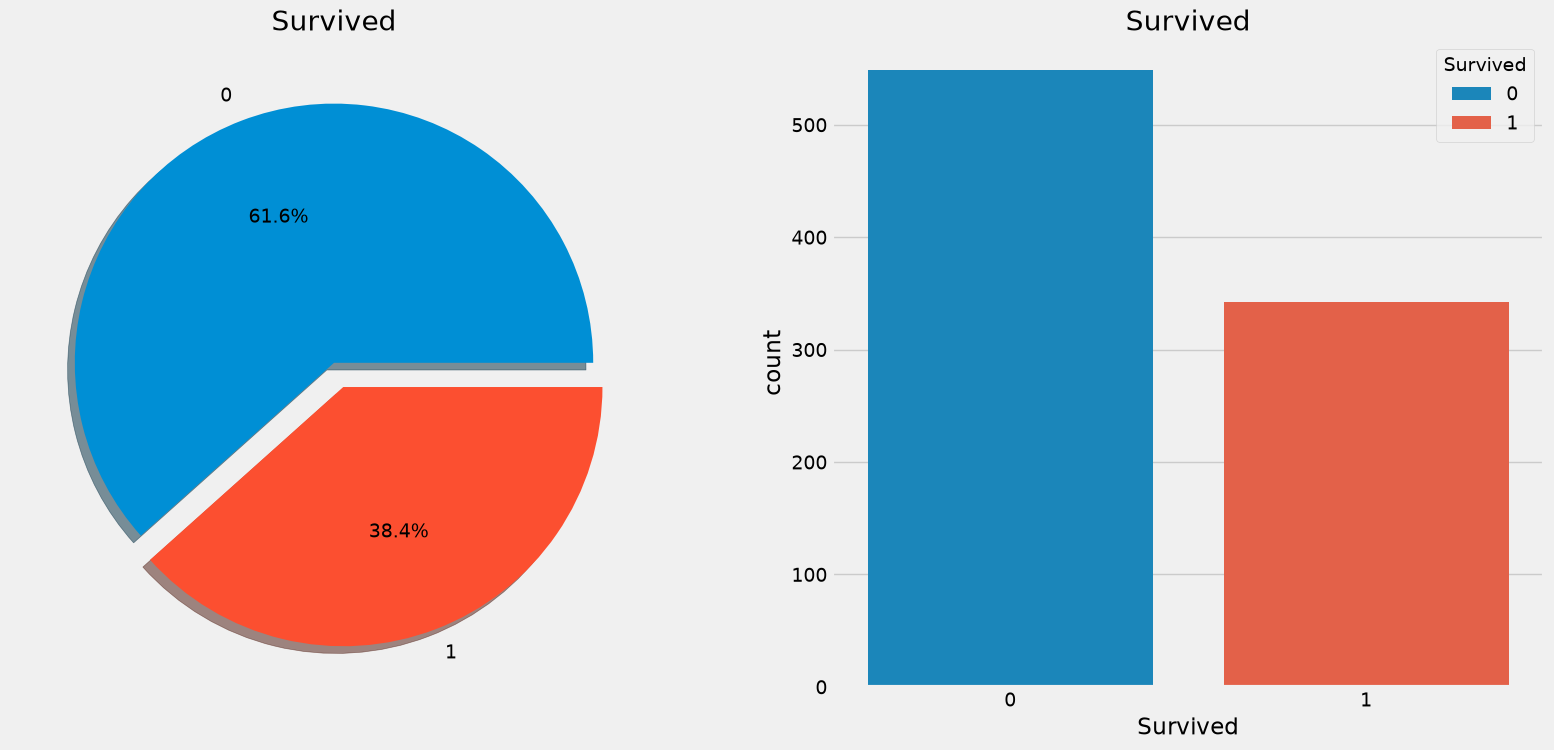

In [45]:
f,ax=plt.subplots(1,2,figsize=(18,8))
data['Survived'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%',ax=ax[0],shadow=True)
ax[0].set_title('Survived')
ax[0].set_ylabel('')
sns.countplot(x ='Survived',data=data,ax=ax[1], hue = 'Survived')
ax[1].set_title('Survived')
plt.show()

Out of 891 passengers in training set, only around 350 survived i.e Only 38.4% of the total training set survived the crash. 

Decent balance of target distribution

We need to dig down more to get better insights from the data and see which categories of the passengers did survive and who didn't.

## Analysing features

Categorical Features in the dataset: Sex,Embarked.

Ordinal Features in the dataset: PClass

Continous Features in the dataset: Age, Fare

Discrete Feature: SibSip

### 1. Sex--> Categorical Feature


In [46]:
data.groupby(['Sex','Survived'])['Survived'].count()

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: Survived, dtype: int64

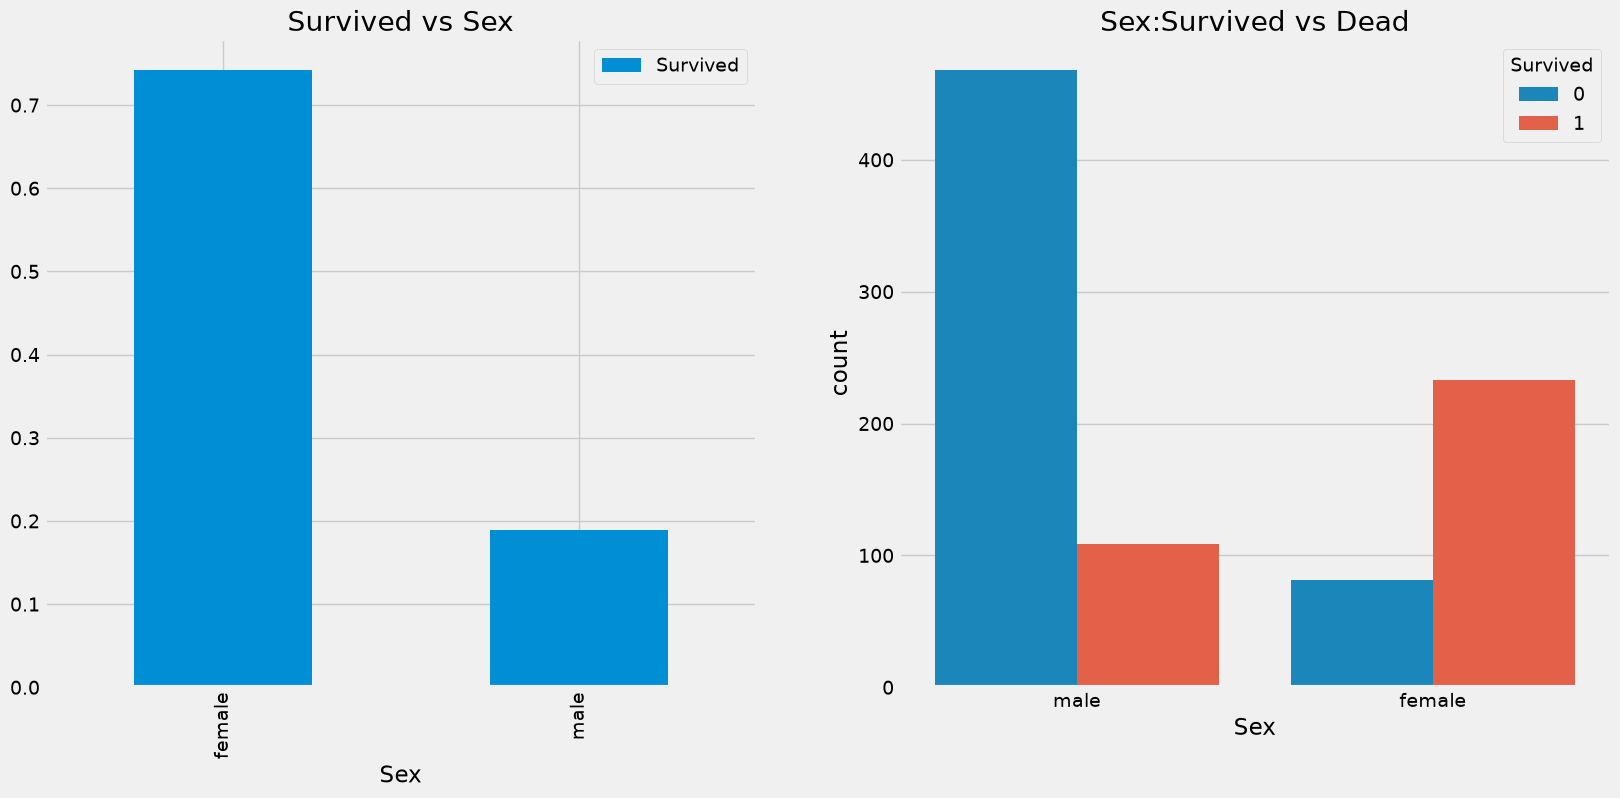

In [47]:
f,ax=plt.subplots(1,2,figsize=(18,8))
data[['Sex','Survived']].groupby(['Sex']).mean().plot.bar(ax=ax[0])
ax[0].set_title('Survived vs Sex')
sns.countplot(x = 'Sex',hue='Survived',data=data,ax=ax[1])
ax[1].set_title('Sex:Survived vs Dead')
plt.show()

The survival rates for a women on the ship is around 75% while that for men in around 18-19%.

This looks to be a very important feature for modeling

### 2. Pclass --> Ordinal Feature

In [48]:
pd.crosstab(data.Pclass,data.Survived,margins=True).style.background_gradient(cmap='summer_r')

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


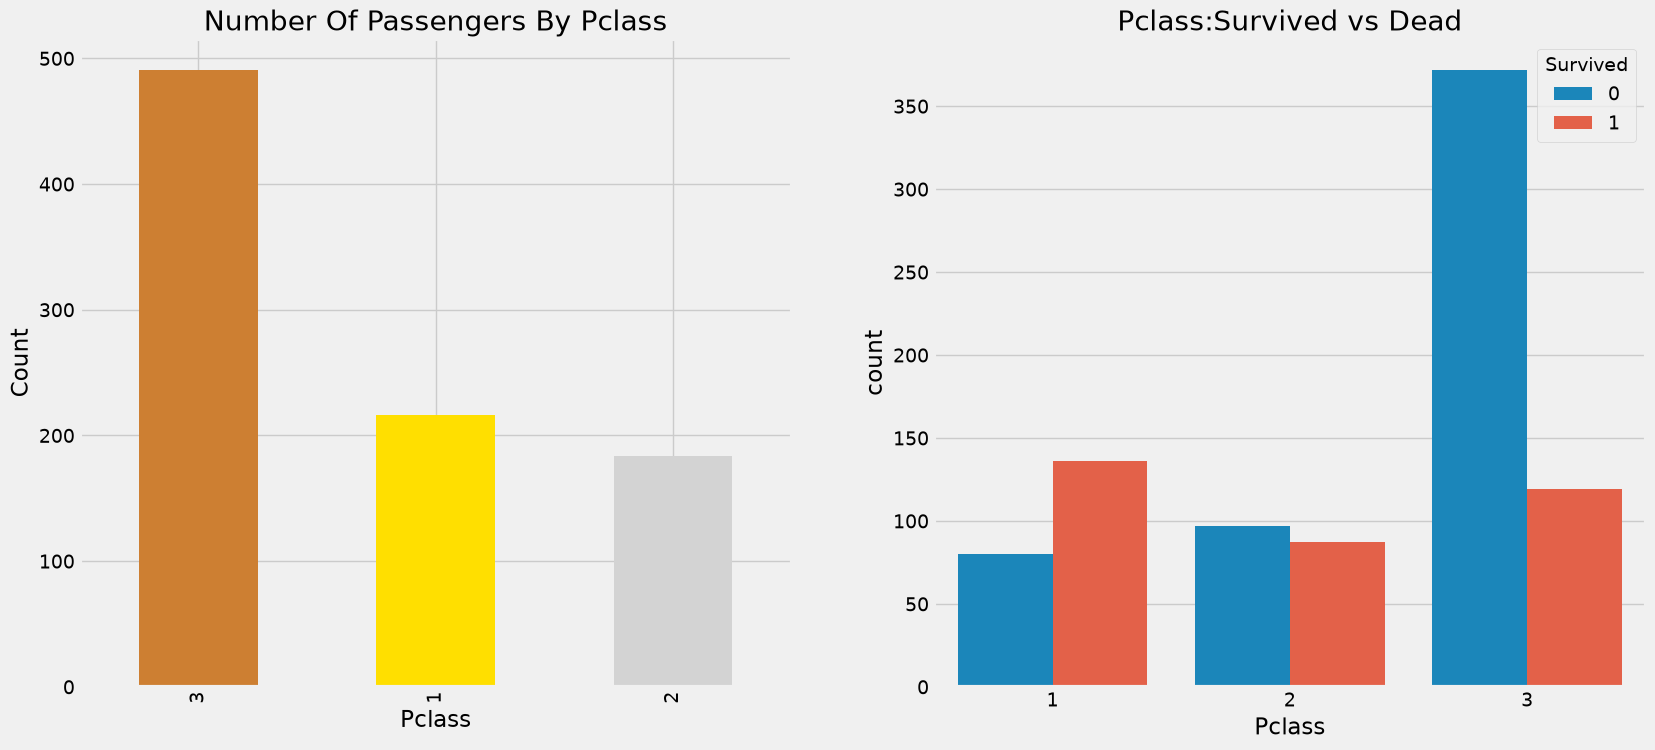

In [49]:
f,ax=plt.subplots(1,2,figsize=(18,8))
data['Pclass'].value_counts().plot.bar(color=['#CD7F32','#FFDF00','#D3D3D3'],ax=ax[0])
ax[0].set_title('Number Of Passengers By Pclass')
ax[0].set_ylabel('Count')
sns.countplot(x = 'Pclass',hue='Survived',data=data,ax=ax[1])
ax[1].set_title('Pclass:Survived vs Dead')
plt.show()

We can clearly see that Passenegers Of Pclass 1 were given a very high priority while rescue. Even though the the number of Passengers in Pclass 3 were a lot higher, still the number of survival from them is very low, somewhere around 25%.

For Pclass 1 %survived is around 63% while for Pclass2 is around 48%

Lets check survival rate with Sex and Pclass Together.

In [50]:
pd.crosstab([data.Sex,data.Survived],data.Pclass,margins=True).style.background_gradient(cmap='summer_r')

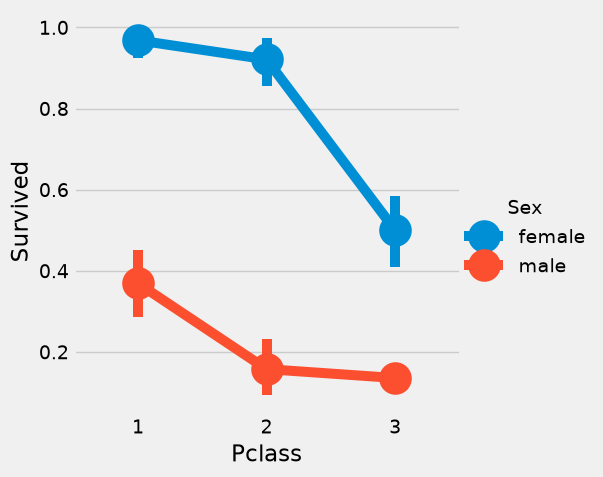

In [51]:
sns.catplot(x='Pclass',y='Survived',hue='Sex',data=data, kind = 'point')
plt.show()


Looking at the CrossTab and the FactorPlot, we can easily infer that survival for Women from Pclass1 is about 95-96%, as only 3 out of 94 Women from Pclass1 died.

It is evident that irrespective of Pclass, Women were given first priority while rescue. Even Men from Pclass1 have a very low survival rate.

Looks like Pclass is also an important feature. Lets analyse other features.

### 3. Age--> Continous Feature

In [52]:
print('Oldest Passenger was of:',data['Age'].max(),'Years')
print('Youngest Passenger was of:',data['Age'].min(),'Years')
print('Average Age on the ship:',data['Age'].mean(),'Years')

Oldest Passenger was of: 80.0 Years
Youngest Passenger was of: 0.42 Years
Average Age on the ship: 29.69911764705882 Years


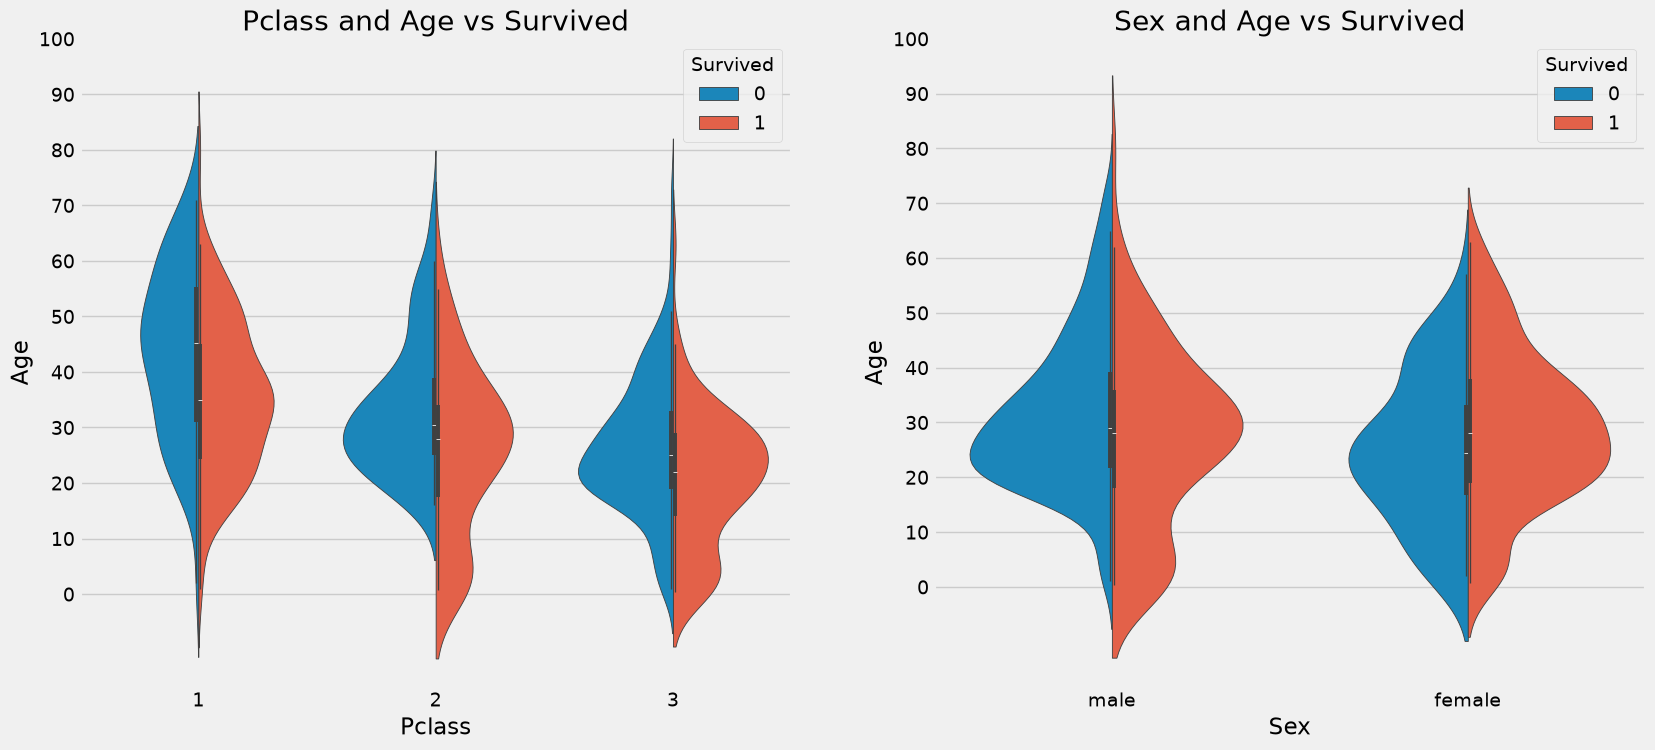

In [53]:
f,ax=plt.subplots(1,2,figsize=(18,8))
sns.violinplot(x="Pclass",y="Age", hue="Survived", data=data,split=True,ax=ax[0])
ax[0].set_title('Pclass and Age vs Survived')
ax[0].set_yticks(range(0,110,10))
sns.violinplot(x="Sex",y="Age", hue="Survived", data=data,split=True,ax=ax[1])
ax[1].set_title('Sex and Age vs Survived')
ax[1].set_yticks(range(0,110,10))
plt.show()

Observations:

1)The number of children increases with Pclass and the survival rate for passenegers below Age 10(i.e children) looks to be good irrespective of the Pclass.

2)Survival chances for Passenegers aged 20-50 from Pclass1 is high and is even better for Women.

3)For males, the survival chances decreases with an increase in age.

#### Replacing Nan values


As we had seen earlier, the Age feature has 177 null values. To replace these NaN values, we can assign them the mean age of the dataset.

But the problem is, there were many people with many different ages. We just cant assign a 4 year kid with the mean age that is 29 years.

 We can check the Name feature. Looking upon the feature, we can see that the names have a salutation like Mr or Mrs. Thus we can assign the mean values of Mr and Mrs to the respective groups.

In [54]:
data['Initial']=0
for i in data:
    data['Initial']=data.Name.str.extract('([A-Za-z]+)\.')

In [55]:
pd.crosstab(data.Initial,data.Sex).T.style.background_gradient(cmap='summer_r') 

Initial,Capt,Col,Countess,Don,Dr,Jonkheer,Lady,Major,Master,Miss,Mlle,Mme,Mr,Mrs,Ms,Rev,Sir
Sex,,,,,,,,,,,,,,,,,
female,0,0,1,0,1,0,1,0,0,182,2,1,0,125,1,0,0
male,1,2,0,1,6,1,0,2,40,0,0,0,517,0,0,6,1


Okay so there are some misspelled Initials like Mlle or Mme that stand for Miss. I will replace them with Miss and same thing for other values.

In [56]:
mapping = {
    'Mlle': 'Miss', 'Mme': 'Miss', 'Ms': 'Miss',
    'Dr': 'Mr', 'Major': 'Mr', 'Capt': 'Mr', 'Sir': 'Mr', 'Don': 'Mr',
    'Lady': 'Mrs', 'Countess': 'Mrs',
    'Jonkheer': 'Other', 'Col': 'Other', 'Rev': 'Other'
}

data['Initial'] = data['Initial'].replace(mapping)

data.groupby('Initial')['Age'].mean()

Initial
Master     4.574167
Miss      21.860000
Mr        32.739609
Mrs       35.981818
Other     45.888889
Name: Age, dtype: float64

In [57]:
## Assigning the NaN Values with the Ceil values of the mean ages
data.loc[(data.Age.isnull())&(data.Initial=='Mr'),'Age']=33
data.loc[(data.Age.isnull())&(data.Initial=='Mrs'),'Age']=36
data.loc[(data.Age.isnull())&(data.Initial=='Master'),'Age']=5
data.loc[(data.Age.isnull())&(data.Initial=='Miss'),'Age']=22
data.loc[(data.Age.isnull())&(data.Initial=='Other'),'Age']=46


In [58]:
data.Age.isnull().any()

np.False_

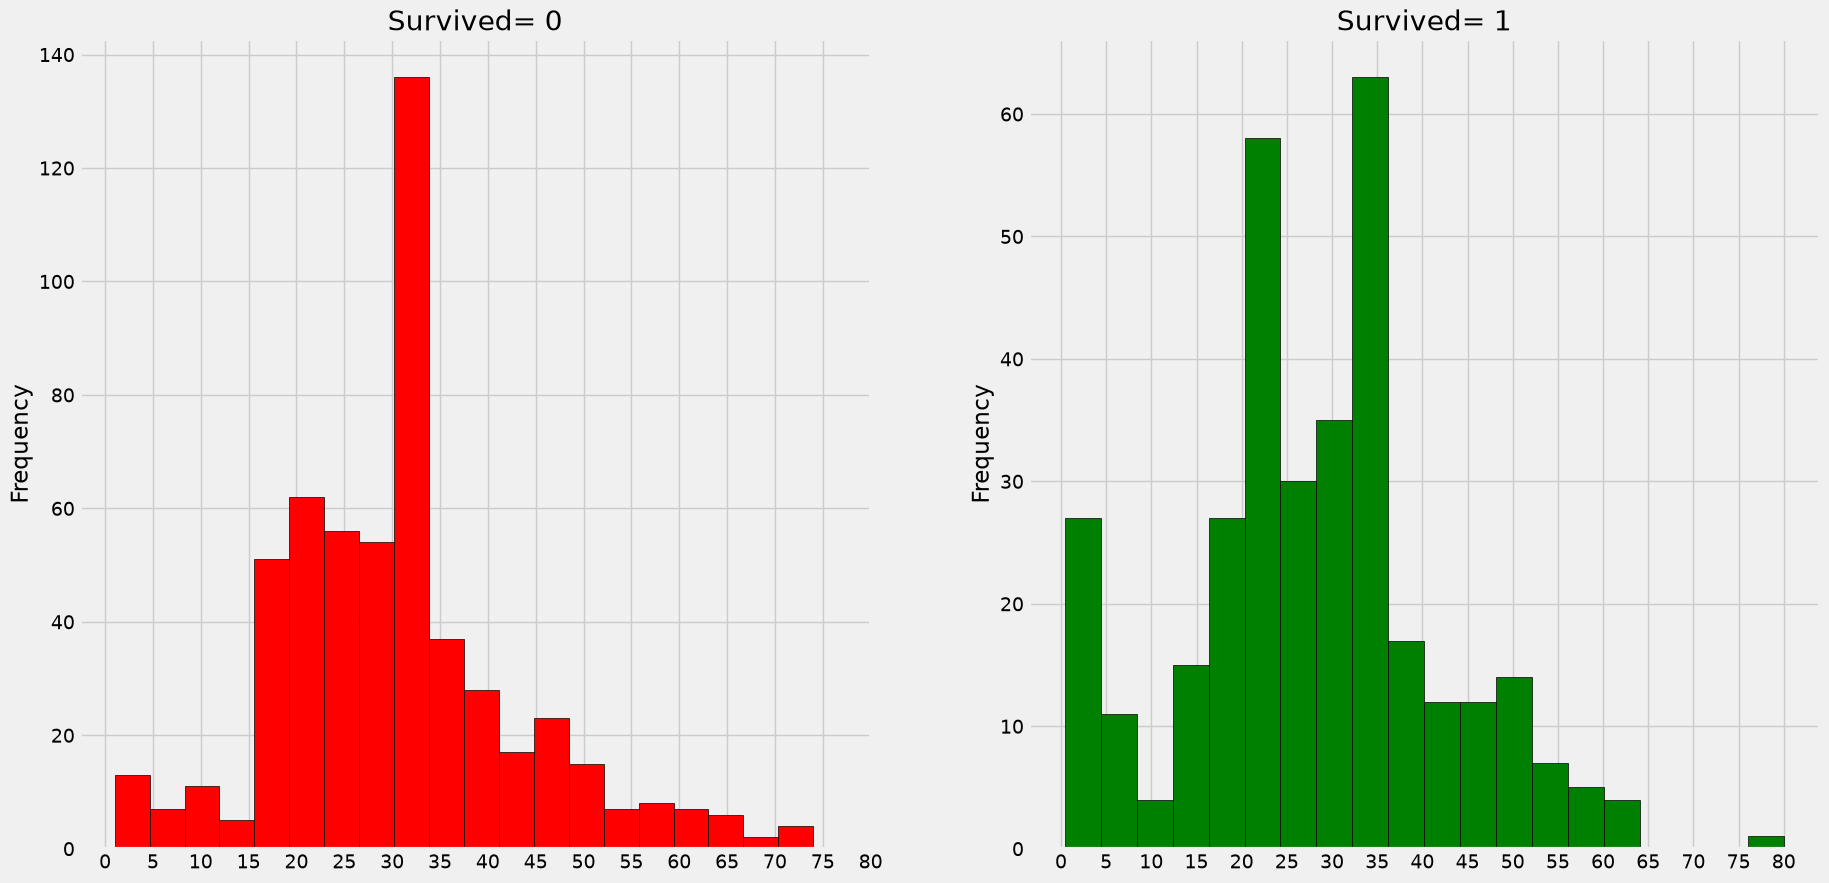

In [59]:
f,ax=plt.subplots(1,2,figsize=(20,10))
data[data['Survived']==0].Age.plot.hist(ax=ax[0],bins=20,edgecolor='black',color='red')
ax[0].set_title('Survived= 0')
x1=list(range(0,85,5))
ax[0].set_xticks(x1)
data[data['Survived']==1].Age.plot.hist(ax=ax[1],color='green',bins=20,edgecolor='black')
ax[1].set_title('Survived= 1')
x2=list(range(0,85,5))
ax[1].set_xticks(x2)
plt.show()

Observations:

1)The Toddlers(age<5) were saved in large numbers(The Women and Child First Policy).

2)The oldest Passenger was saved(80 years).

3)Maximum number of deaths were in the age group of 30-40.

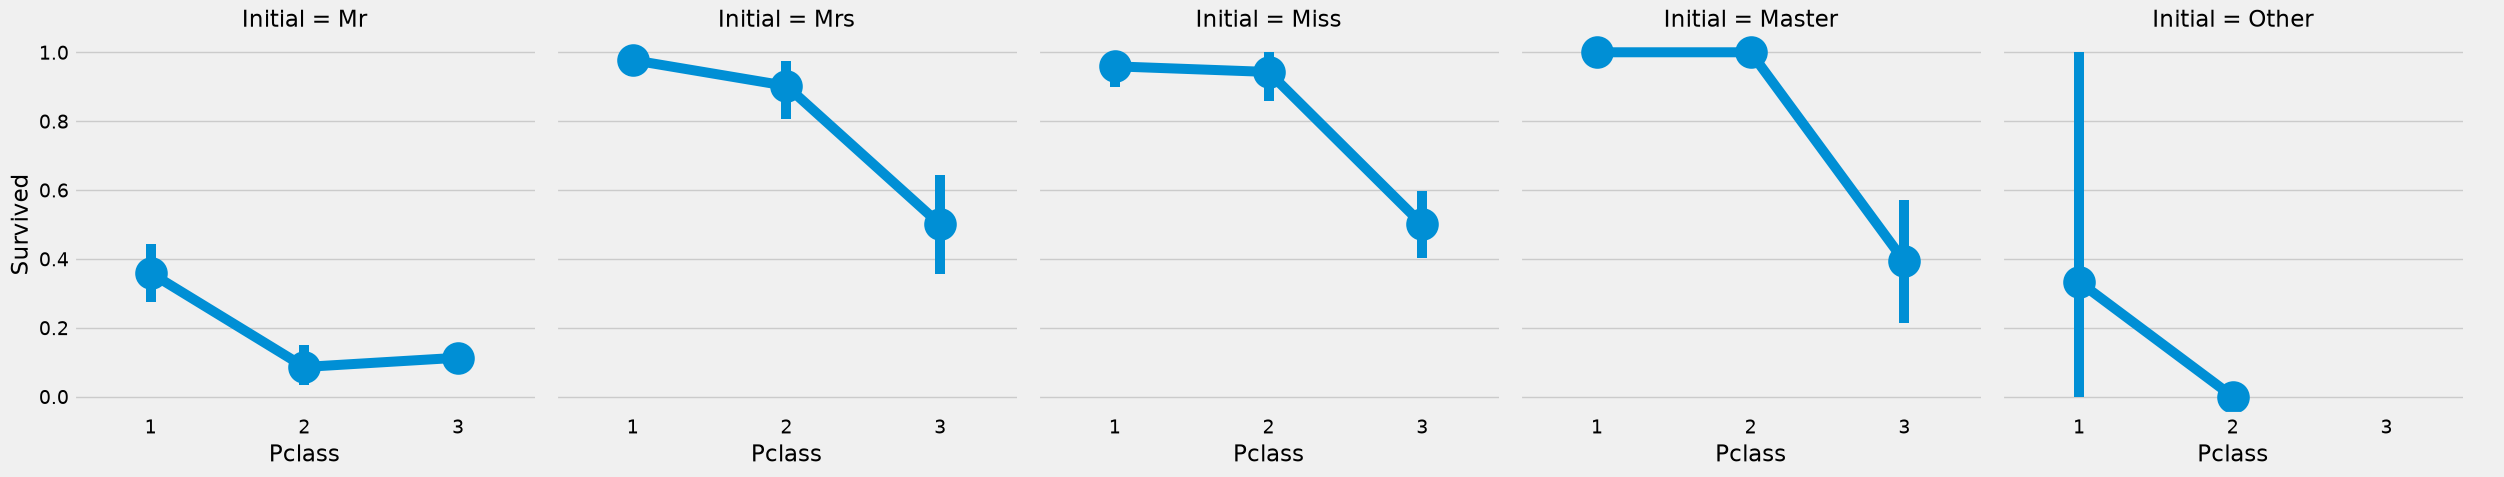

In [60]:
sns.catplot(x='Pclass',y='Survived',col='Initial',data=data,kind = 'point')
plt.show()

The Women and Child first policy thus holds true irrespective of the class.

### 4.Embarked--> Categorical Value

In [61]:
pd.crosstab([data.Embarked,data.Pclass],[data.Sex,data.Survived],margins=True).style.background_gradient(cmap='summer_r')

Chances for Survival by Port Of Embarkation

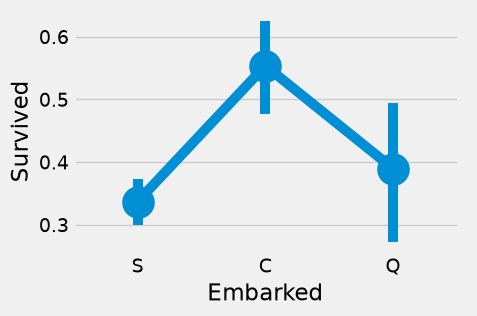

In [62]:
sns.catplot(x='Embarked',y='Survived',data=data, kind = 'point')
fig=plt.gcf()
fig.set_size_inches(5,3)
plt.show()

The chances for survival for Port C is highest around 0.55 while it is lowest for S.

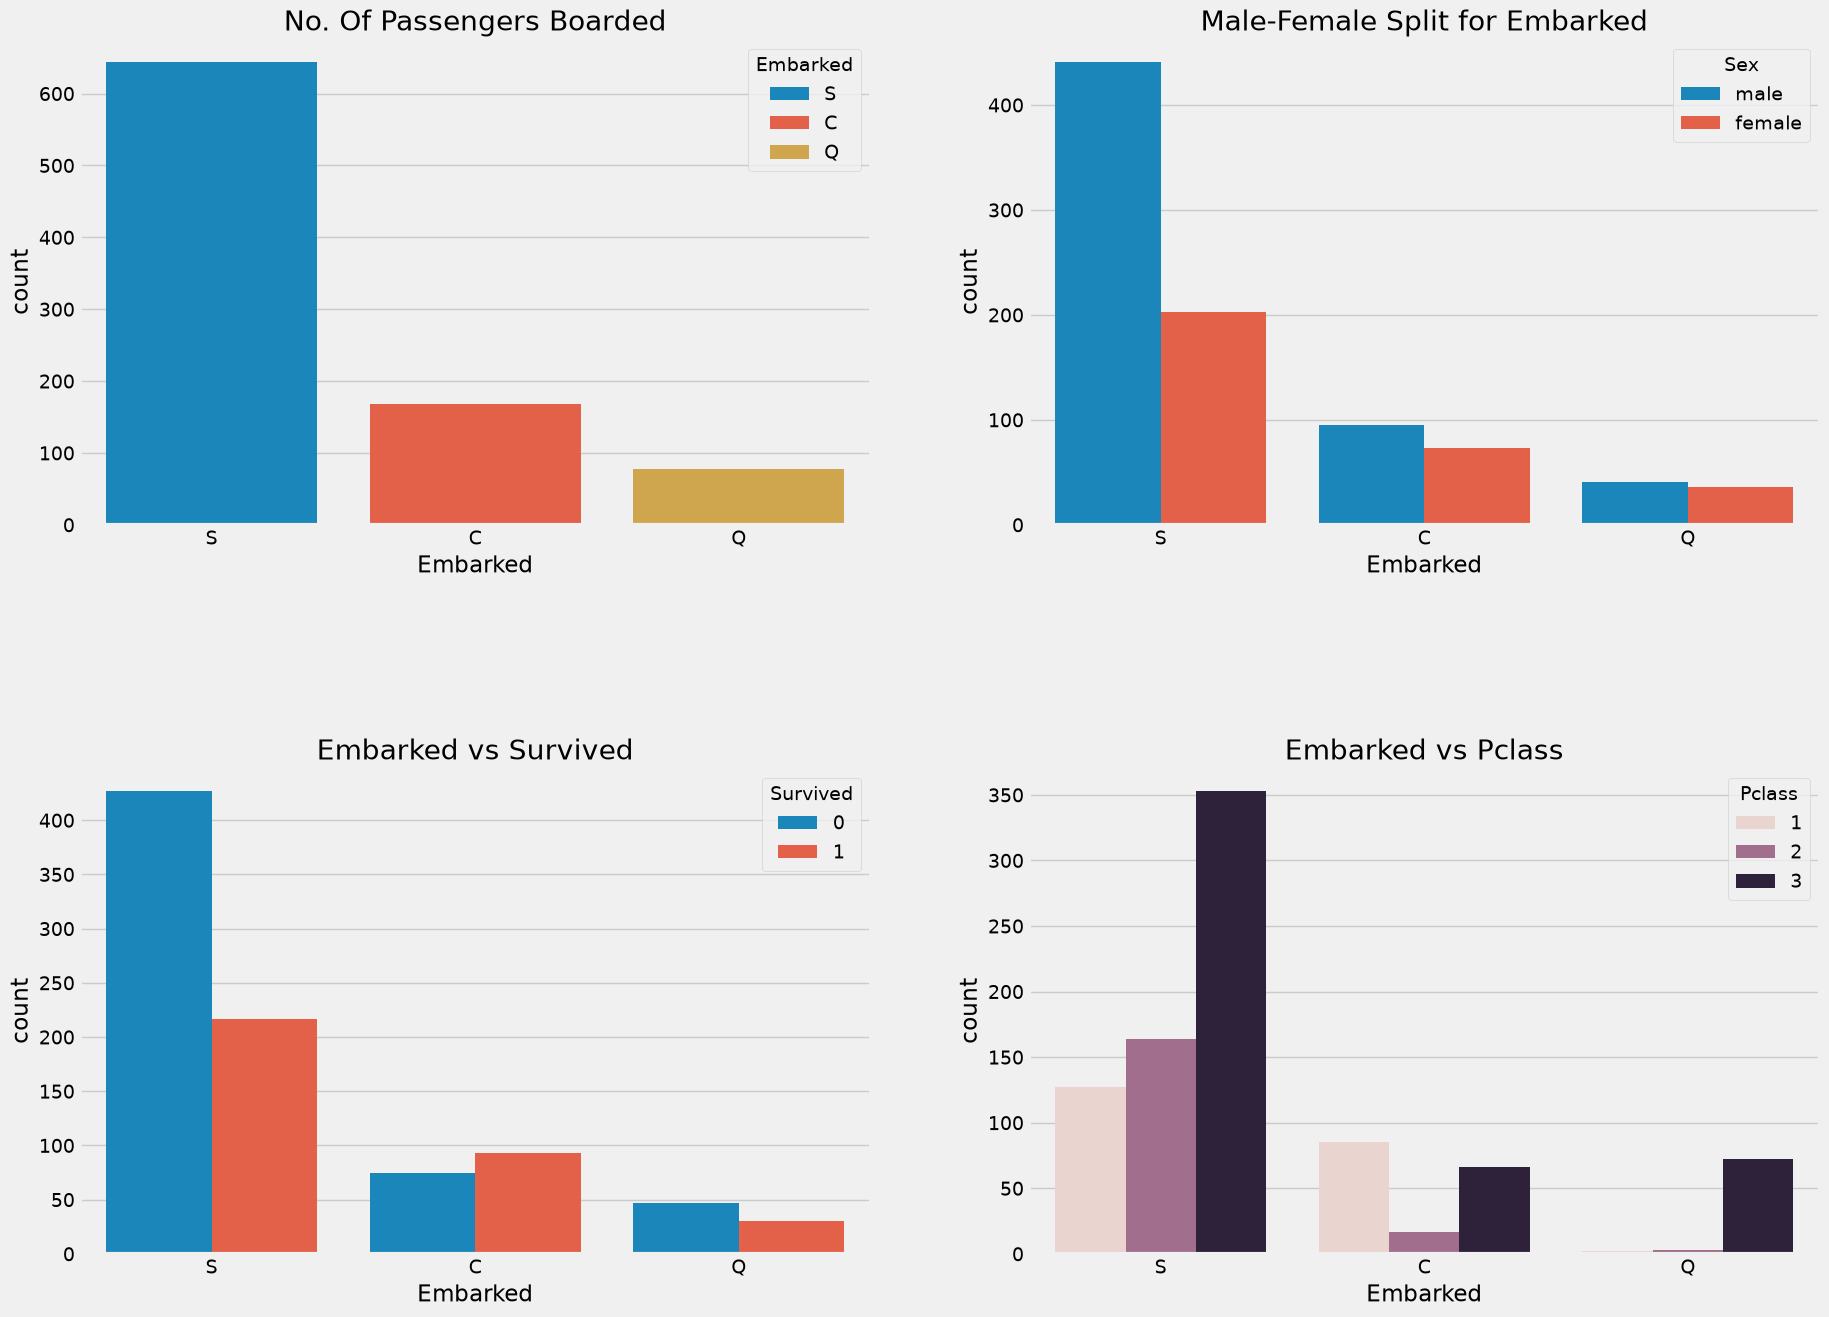

In [63]:
f,ax=plt.subplots(2,2,figsize=(20,15))
sns.countplot(x='Embarked',data=data,ax=ax[0,0],hue='Embarked')
ax[0,0].set_title('No. Of Passengers Boarded')
sns.countplot(x='Embarked',hue='Sex',data=data,ax=ax[0,1])
ax[0,1].set_title('Male-Female Split for Embarked')
sns.countplot(x='Embarked',hue='Survived',data=data,ax=ax[1,0])
ax[1,0].set_title('Embarked vs Survived')
sns.countplot(x='Embarked',hue='Pclass',data=data,ax=ax[1,1])
ax[1,1].set_title('Embarked vs Pclass')
plt.subplots_adjust(wspace=0.2,hspace=0.5)
plt.show()

Observations:

1)Maximum passenegers boarded from S. Majority of them being from Pclass3.

2)The Passengers from C look to be lucky as a good proportion of them survived. The reason for this maybe the rescue of all the Pclass1 and Pclass2 Passengers.

3)The Embark S looks to the port from where majority of the rich people boarded. Still the chances for survival is low here, that is because many passengers from Pclass3 around 81% didn't survive.

4)Port Q had almost 95% of the passengers were from Pclass3.

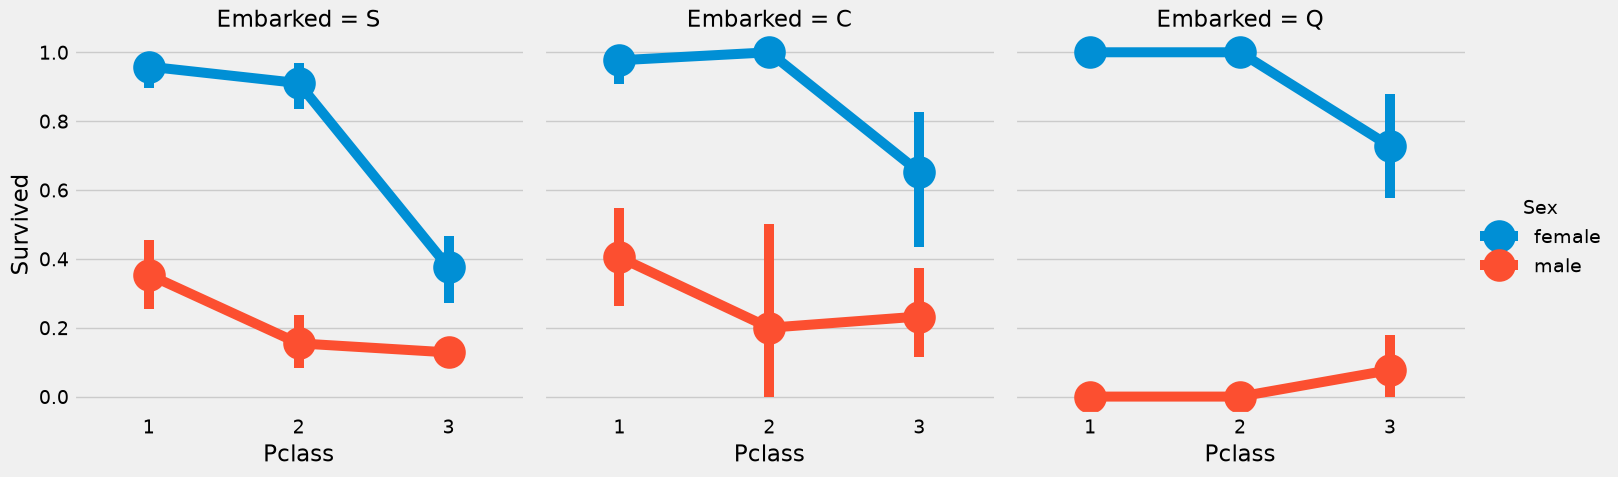

In [64]:
sns.catplot(x='Pclass',y='Survived',hue='Sex',col='Embarked',data=data, kind = 'point')
plt.show()

Observations:

1)The survival chances are almost 1 for women for Pclass1 and Pclass2 irrespective of the Pclass.

2)Port S looks to be very unlucky for Pclass3 Passenegers as the survival rate for both men and women is very low.(Money Matters)

3)Port Q looks looks to be unlukiest for Men, as almost all were from Pclass 3.

#### Filling Embarked NaN

As we saw that maximum passengers boarded from Port S, we replace NaN with S

In [65]:
data['Embarked']=data['Embarked'].fillna('S')

In [66]:
data.Embarked.isnull().any()

np.False_

### 5. SibSip-->Discrete Feature

This feature represents whether a person is alone or with his family members.

Sibling = brother, sister, stepbrother, stepsister

Spouse = husband, wife

In [67]:
pd.crosstab([data.SibSp],data.Survived).style.background_gradient(cmap='summer_r')

Survived,0,1
SibSp,,
0,398,210
1,97,112
2,15,13
3,12,4
4,15,3
5,5,0
8,7,0


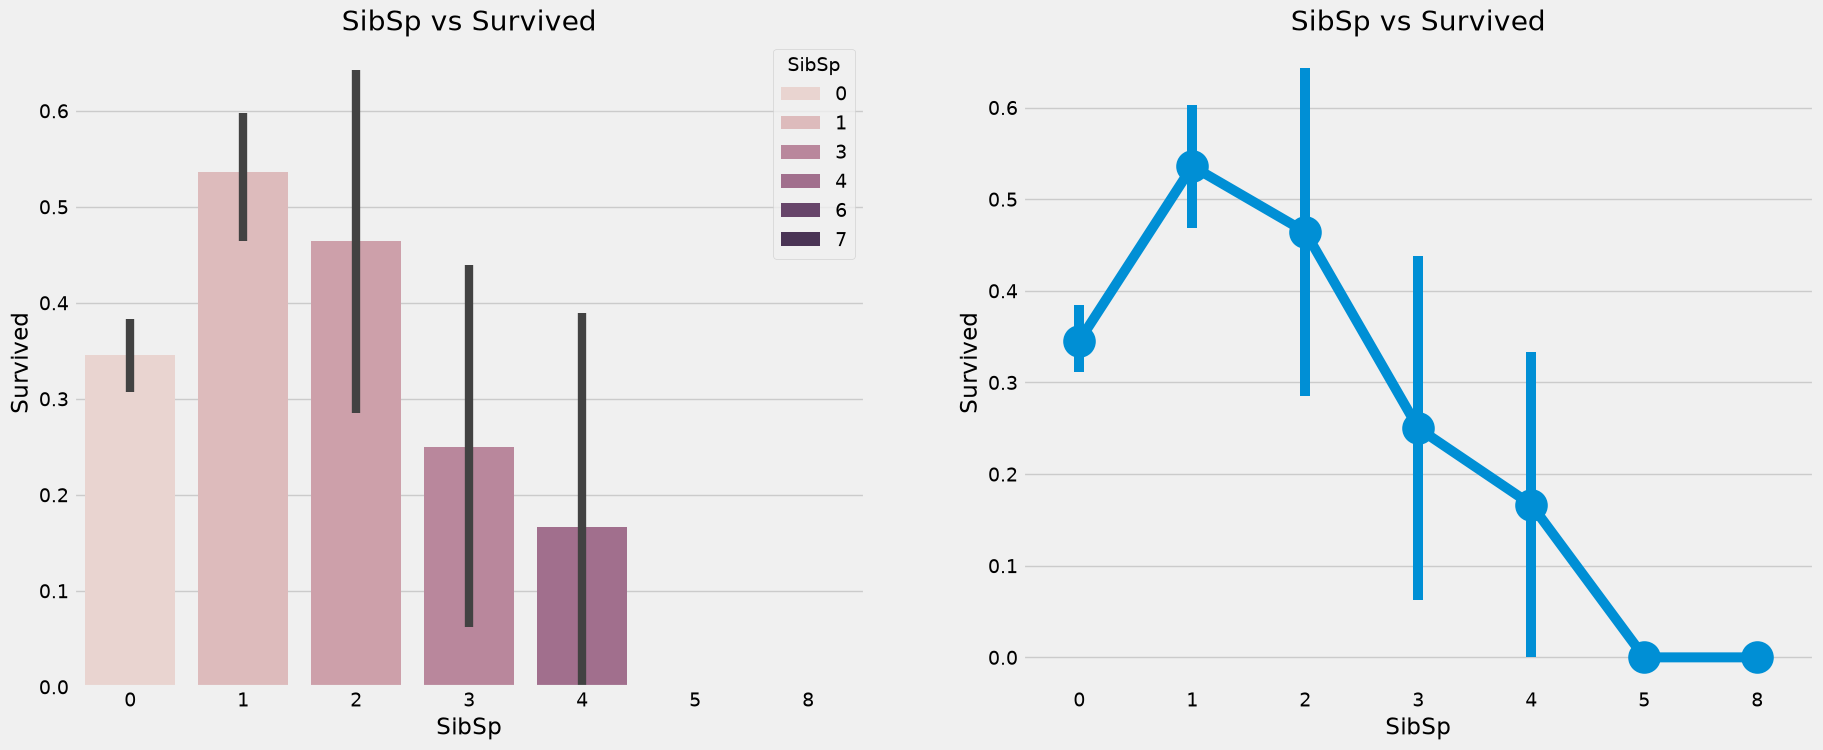

In [68]:
f,ax=plt.subplots(1,2,figsize=(20,8))
sns.barplot(x='SibSp',y='Survived',data=data,ax=ax[0], hue = 'SibSp')
ax[0].set_title('SibSp vs Survived')
sns.pointplot(x='SibSp',y='Survived',data=data,ax=ax[1])
ax[1].set_title('SibSp vs Survived')
plt.close(2)
plt.show()

In [69]:
pd.crosstab(data.SibSp,data.Pclass).style.background_gradient(cmap='summer_r')

Pclass,1,2,3
SibSp,,,
0,137,120,351
1,71,55,83
2,5,8,15
3,3,1,12
4,0,0,18
5,0,0,5
8,0,0,7


Observations:

The barplot and factorplot shows that if a passenger is alone onboard with no siblings, he have 34.5% survival rate. The graph roughly decreases if the number of siblings increase. This makes sense. That is, if I have a family on board, I will try to save them instead of saving myself first. Surprisingly the survival for families with 5-8 members is 0%. The reason may be Pclass??

The reason is Pclass. The crosstab shows that Person with SibSp>3 were all in Pclass3. It is imminent that all the large families in Pclass3(>3) died.

#### Parch

In [70]:
pd.crosstab(data.Parch,data.Pclass).style.background_gradient(cmap='summer_r')

Pclass,1,2,3
Parch,,,
0,163,134,381
1,31,32,55
2,21,16,43
3,0,2,3
4,1,0,3
5,0,0,5
6,0,0,1


The crosstab again shows that larger families were in Pclass3.

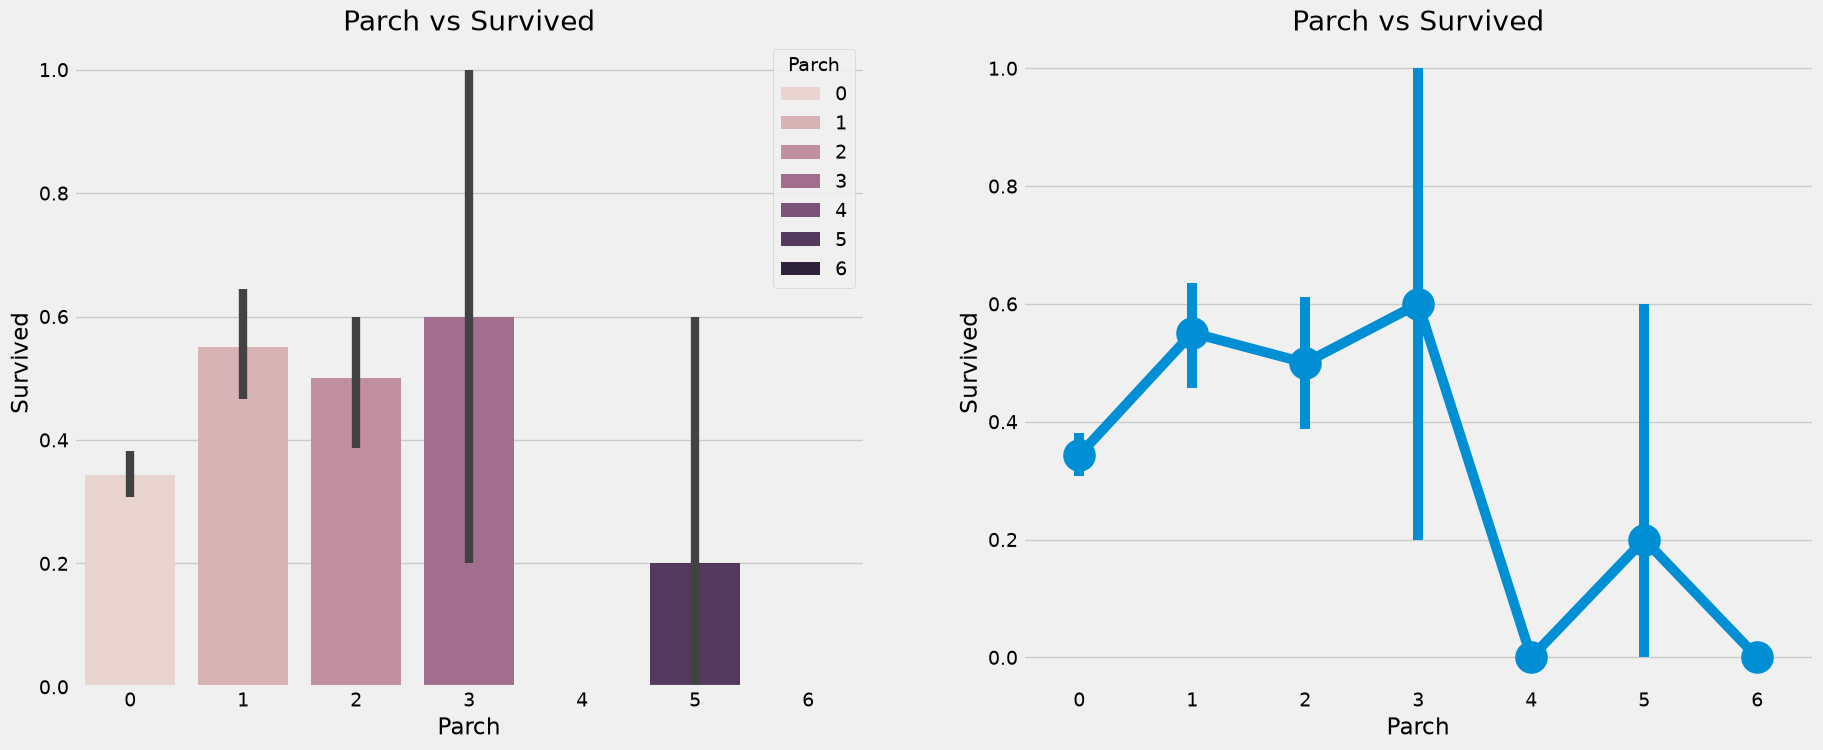

In [71]:
f,ax=plt.subplots(1,2,figsize=(20,8))
sns.barplot(x='Parch',y='Survived',data=data,ax=ax[0], hue = 'Parch')
ax[0].set_title('Parch vs Survived')
sns.pointplot(x='Parch',y='Survived',data=data,ax=ax[1])
ax[1].set_title('Parch vs Survived')
plt.close(2)
plt.show()

Observations:

Here too the results are quite similar. Passengers with their parents onboard have greater chance of survival. It however reduces as the number goes up.

The chances of survival is good for somebody who has 1-3 parents on the ship. Being alone also proves to be fatal and the chances for survival decreases when somebody has >4 parents on the ship.

### 6. Fare--> Continous Feature

In [72]:
print('Highest Fare was:',data['Fare'].max())
print('Lowest Fare was:',data['Fare'].min())
print('Average Fare was:',data['Fare'].mean())

Highest Fare was: 512.3292
Lowest Fare was: 0.0
Average Fare was: 32.204207968574636


0 price might have been for the team members

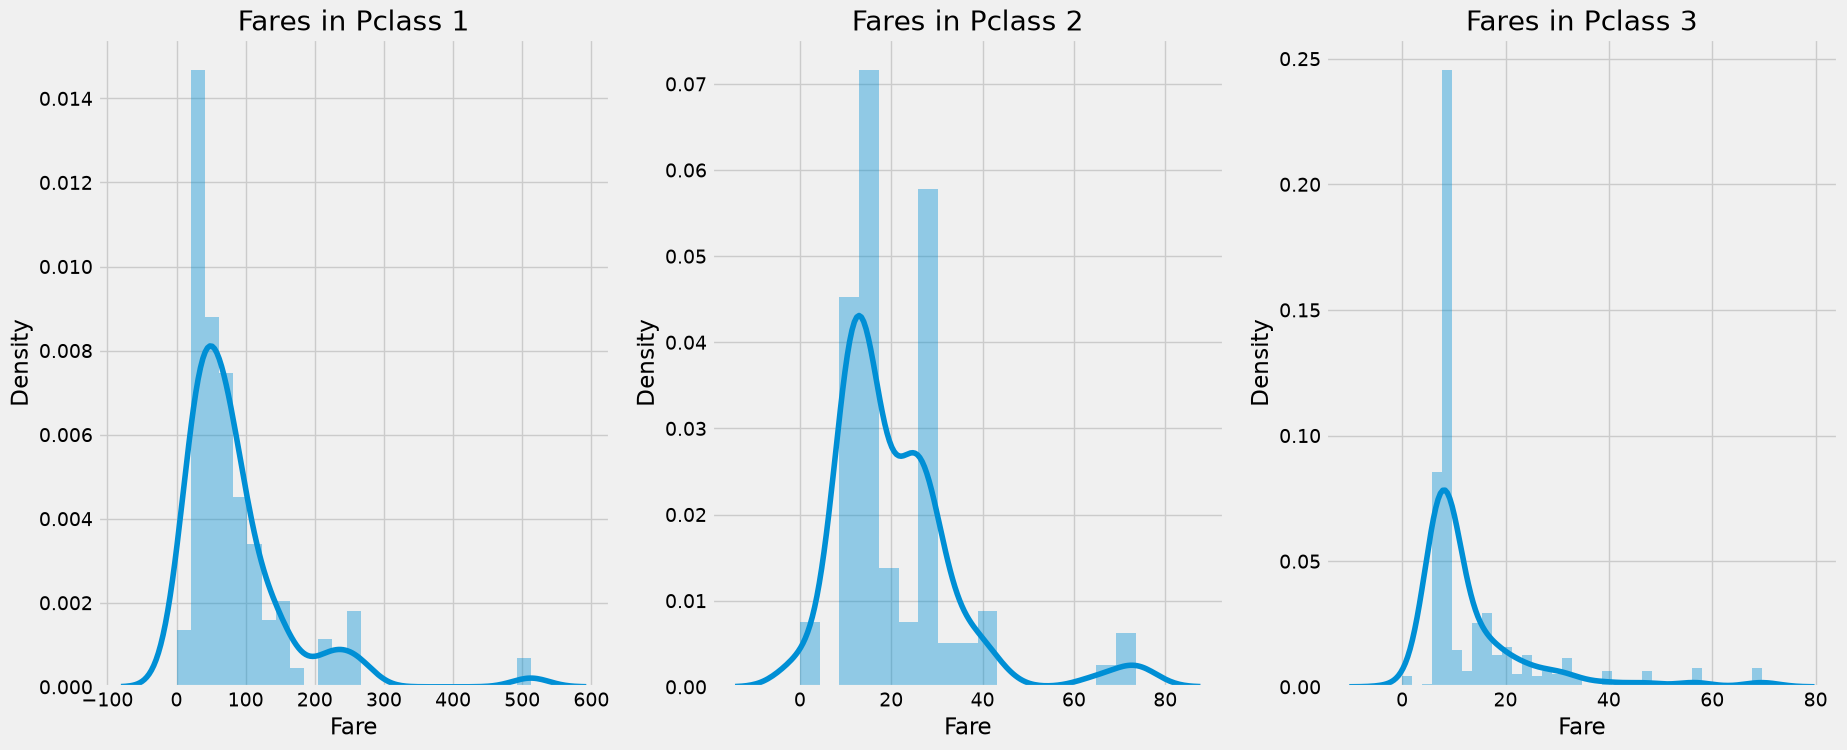

In [73]:
f,ax=plt.subplots(1,3,figsize=(20,8))
sns.distplot(data[data['Pclass']==1].Fare,ax=ax[0])
ax[0].set_title('Fares in Pclass 1')
sns.distplot(data[data['Pclass']==2].Fare,ax=ax[1])
ax[1].set_title('Fares in Pclass 2')
sns.distplot(data[data['Pclass']==3].Fare,ax=ax[2])
ax[2].set_title('Fares in Pclass 3')
plt.show()

There looks to be a large distribution in the fares of Passengers in Pclass1 and this distribution goes on decreasing as the standards reduces. As this is also continous, we can convert into discrete values by using binning.

### Observations in a Nutshell for all features:

Sex: 

The chance of survival for women is high as compared to men.

Pclass:

There is a visible trend that being a 1st class passenger gives you better chances of survival. The survival rate for Pclass3 is very low. For women, the chance of survival from Pclass1 is almost 1 and is high too for those from Pclass2. Money Wins!!!.

Age: 

Children less than 5-10 years do have a high chance of survival. Passengers between age group 15 to 35 died a lot.

Embarked: 

This is a very interesting feature. The chances of survival at C looks to be better than even though the majority of Pclass1 passengers got up at S. Passengers at Q were all from Pclass3.

Parch+SibSp: 

Having 1-2 siblings,spouse on board or 1-3 Parents shows a greater chance of probablity rather than being alone or having a large family travelling with you.

## Correlation Between The Features

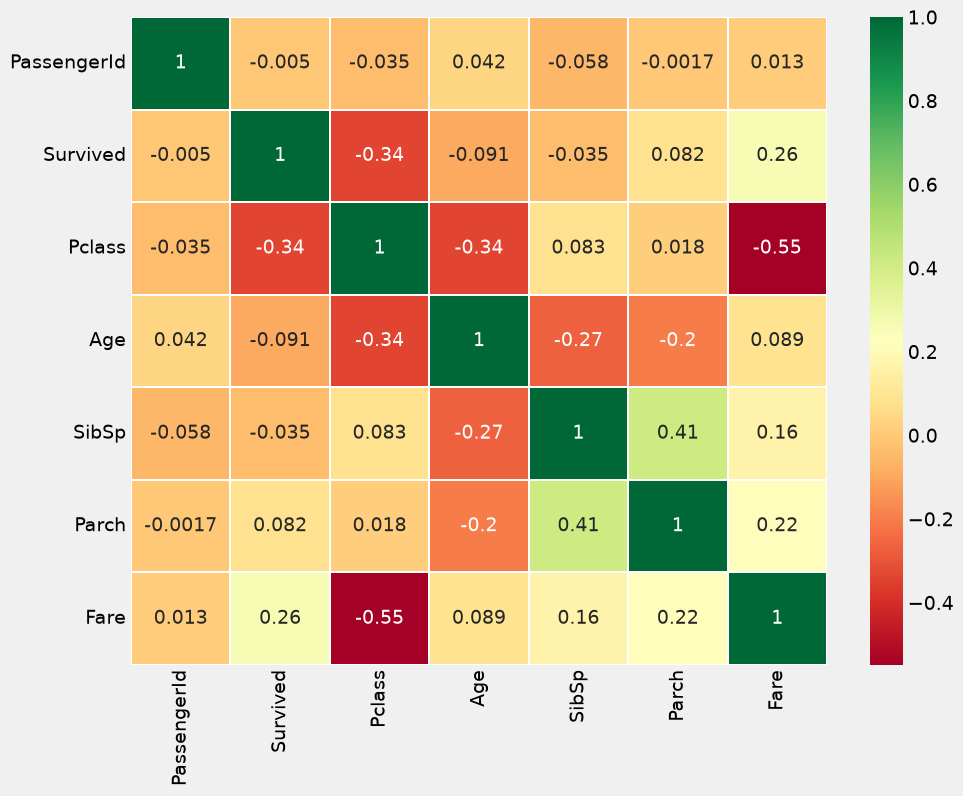

In [76]:
sns.heatmap(data.corr(numeric_only=True),annot=True,cmap='RdYlGn',linewidths=0.2) #data.corr()-->correlation matrix
fig=plt.gcf()
fig.set_size_inches(10,8)
plt.show()

We can see that the features are not much correlated. The highest correlation is between SibSp and Parch i.e 0.41. So we can carry on with all features.

# Prepocessing

We will preprocess our data and after each modification examine metric's change

In [128]:
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier 
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

In [104]:
#A function that will fit the model and print metric
def fit_model(models, data, target):

    y = target
    X = data
    X_train,X_val,y_train, y_val = train_test_split(X, y, test_size=0.8, random_state=42)

    for model in models:
        model.fit(X_train,y_train)
        prediction = model.predict(X_val)

        print(f"Accuracy for {model}:", metrics.accuracy_score(prediction,y_val))





In [105]:
models = [LogisticRegression(),svm.SVC(), RandomForestClassifier(random_state = 42)]


## 1. Metric without preprocessing

In [146]:
data = pd.read_csv('data/train.csv')
print(data.columns)
nums_features = ['Pclass','Age', 'SibSp','Parch', 'Fare']
cat_features = ['Sex', 'Embarked']

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')


In [107]:
#Nan are excluded
data = data.dropna(subset=nums_features)
data1=data[nums_features]
target=data['Survived']

In [108]:
fit_model(models,data1,target)

Accuracy for LogisticRegression(): 0.6923076923076923
Accuracy for SVC(): 0.6555944055944056
Accuracy for RandomForestClassifier(random_state=42): 0.7062937062937062


## 2. Fill Nan values

In [149]:
data = pd.read_csv('data/train.csv')
nums_features = ['Pclass','Age', 'SibSp','Parch', 'Fare']
cat_features = ['Sex', 'Embarked']

In [121]:
def data_fillna(data):
    data['Initial']=0
    for i in data:
        data['Initial']=data.Name.str.extract('([A-Za-z]+)\.')
    mapping = {
    'Mlle': 'Miss', 'Mme': 'Miss', 'Ms': 'Miss',
    'Dr': 'Mr', 'Major': 'Mr', 'Capt': 'Mr', 'Sir': 'Mr', 'Don': 'Mr',
    'Lady': 'Mrs', 'Countess': 'Mrs',
    'Jonkheer': 'Other', 'Col': 'Other', 'Rev': 'Other'
}

    data['Initial'] = data['Initial'].replace(mapping)

    data.loc[(data.Age.isnull())&(data.Initial=='Mr'),'Age']=33
    data.loc[(data.Age.isnull())&(data.Initial=='Mrs'),'Age']=36
    data.loc[(data.Age.isnull())&(data.Initial=='Master'),'Age']=5
    data.loc[(data.Age.isnull())&(data.Initial=='Miss'),'Age']=22
    data.loc[(data.Age.isnull())&(data.Initial=='Other'),'Age']=46

    data['Embarked']=data['Embarked'].fillna('S')

    return data

In [150]:
data2 = data_fillna(data)
target = data2['Survived']
data2 = data2[nums_features]
data2.isnull().any()

Pclass    False
Age       False
SibSp     False
Parch     False
Fare      False
dtype: bool

In [151]:
fit_model(models,data2, target)

Accuracy for LogisticRegression(): 0.6984572230014026
Accuracy for SVC(): 0.6521739130434783
Accuracy for RandomForestClassifier(random_state=42): 0.667601683029453


Improve for LogReg

## 3. Normalize

In [140]:
def data_normal(data, scaler = None):
    if scaler is None:
        scaler = StandardScaler()
    data['Age'] = scaler.fit_transform(data[['Age']])
    data['Fare'] = scaler.fit_transform(data[['Fare']])

    return data

In [152]:
data3 = data_normal(data2)
fit_model(models, data3,target)

Accuracy for LogisticRegression(): 0.699859747545582
Accuracy for SVC(): 0.7166900420757363
Accuracy for RandomForestClassifier(random_state=42): 0.6746143057503506


Improved accuracy for all models

## 4. Feature engineering

### Family_Size and Alone

At this point, we can create a new feature called "Family_size" and "Alone" and analyse it

This feature is the summation of Parch and SibSp. It gives us a combined data so that we can check if survival rate have anything to do with family size of the passengers. Alone will denote whether a passenger is alone or not.

In [142]:
def data_famaly_size(data):
    data['Family_Size']=0
    data['Family_Size']=data['Parch']+data['SibSp']#family size
    data['Alone']=0
    data.loc[data.Family_Size==0,'Alone']=1
    
    return data

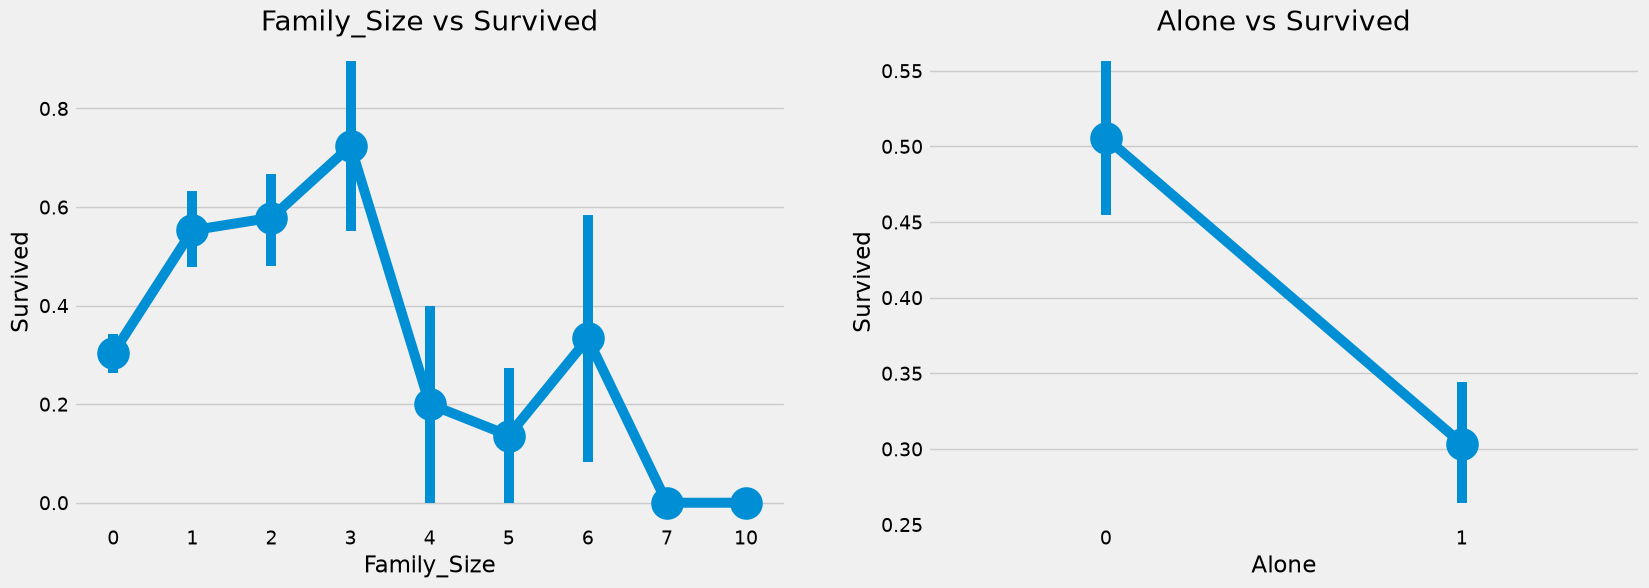

In [143]:
data['Family_Size']=0
data['Family_Size']=data['Parch']+data['SibSp']#family size
data['Alone']=0
data.loc[data.Family_Size==0,'Alone']=1#Alone

f,ax=plt.subplots(1,2,figsize=(18,6))
sns.pointplot(x='Family_Size',y = 'Survived',data=data,ax=ax[0])
ax[0].set_title('Family_Size vs Survived')
sns.pointplot(x = 'Alone', y = 'Survived',data=data,ax=ax[1])
ax[1].set_title('Alone vs Survived')
plt.close(2)
plt.close(3)
plt.show()

Family_Size=0 means that the passeneger is alone. Clearly, if you are alone or family_size=0,then chances for survival is very low. For family size > 4,the chances decrease too. This also looks to be an important feature for the model. Lets examine this further.

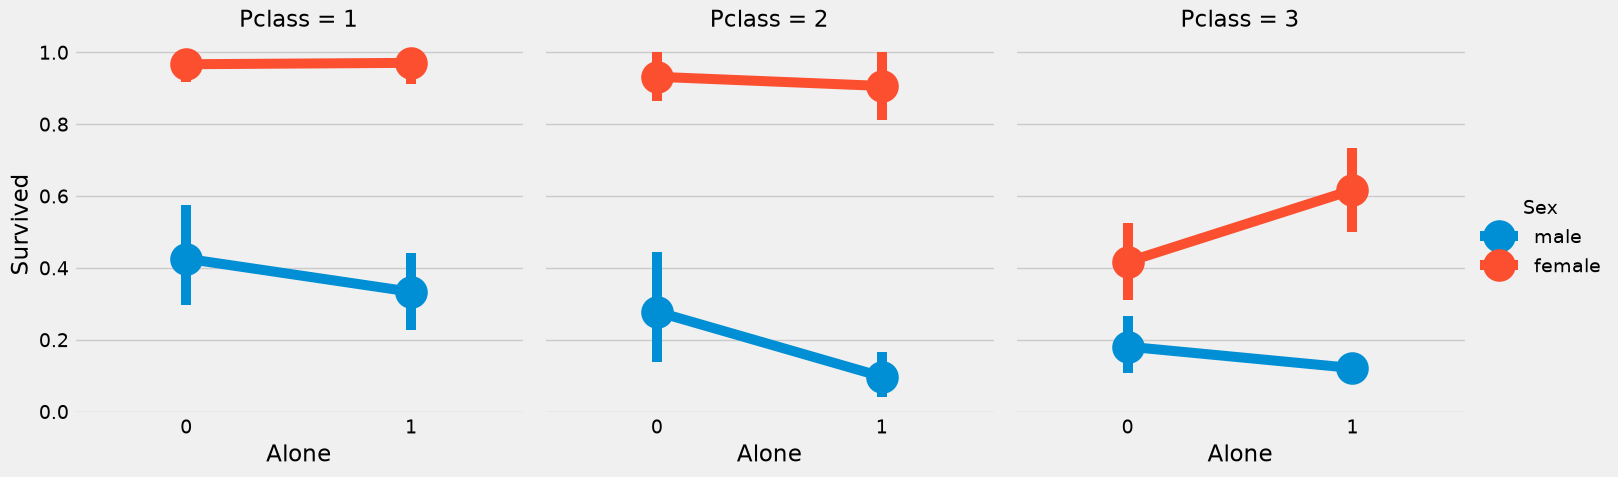

In [144]:
sns.catplot(x='Alone',y='Survived',data=data,hue='Sex',col='Pclass', kind = 'point')
plt.show()

It is visible that being alone is harmful irrespective of Sex or Pclass except for Pclass3 where the chances of females who are alone is high than those with family.

In [ ]:
data4 = data_famaly_size(data3)
fit_model(models, data4, target)

Accuracy for LogisticRegression(): 0.726507713884993
Accuracy for SVC(): 0.7040673211781207
Accuracy for RandomForestClassifier(random_state=42): 0.6704067321178121


can see improvement for LogReg

### Converting String Values into Numeric

In [164]:
def convert_string_to_num(data):
    data['Sex'] = data['Sex'].replace(['male','female'],[0,1])
    data['Embarked'] = data['Embarked'].replace(['S','C','Q'],[0,1,2])
    data['Initial'] = data['Initial'].replace(['Mr','Mrs','Miss','Master','Other'],[0,1,2,3,4])

    return data
    

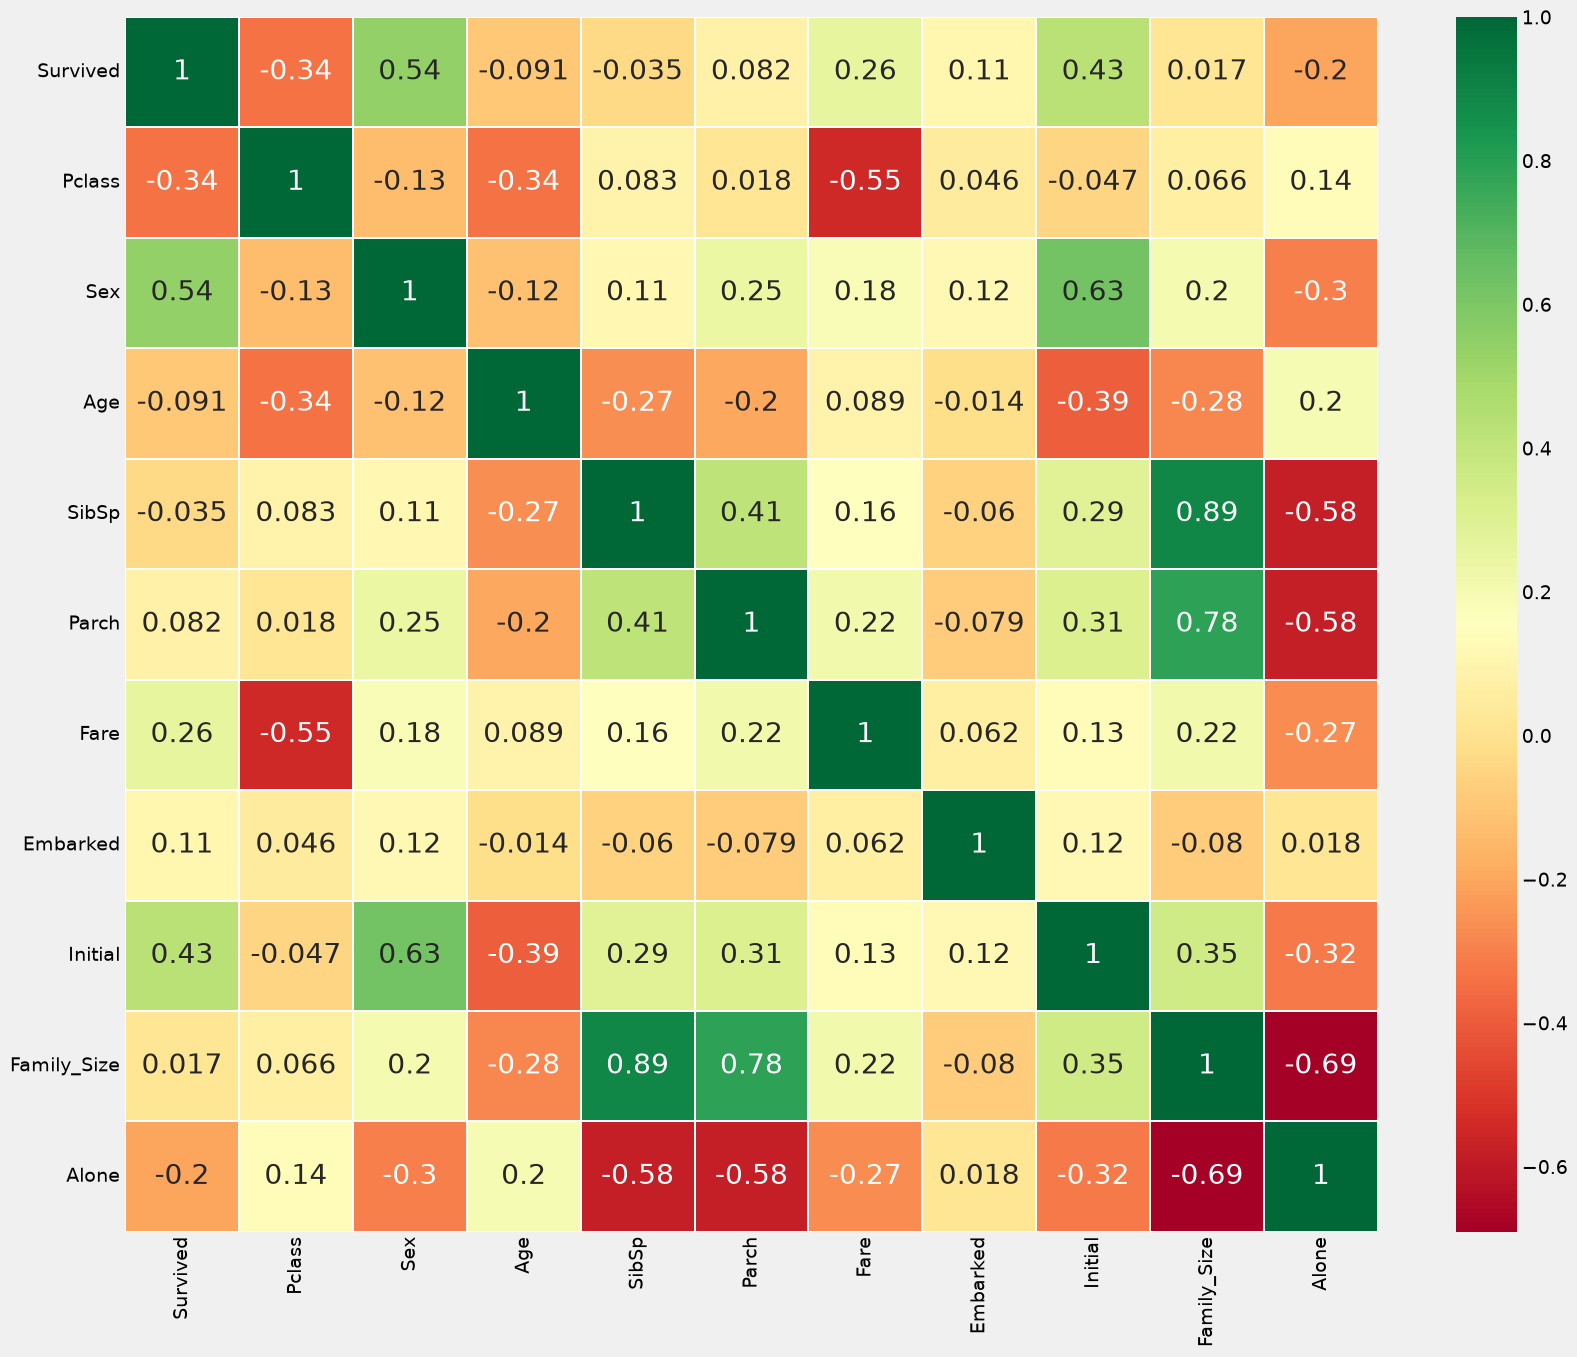

In [172]:
data = pd.read_csv('data/train.csv')
data = data_fillna(data)
data = data_normal(data)
data = data_famaly_size(data)
data = convert_string_to_num(data)

data = data.drop(['Name','Ticket','Cabin','PassengerId'],axis=1)

sns.heatmap(data.corr(),annot=True,cmap='RdYlGn',linewidths=0.2,annot_kws={'size':20})
fig=plt.gcf()
fig.set_size_inches(18,15)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [173]:
target = data['Survived']
data = data.drop(columns=['Survived'])


In [174]:
fit_model(models,data,target)

Accuracy for LogisticRegression(): 0.7966339410939691
Accuracy for SVC(): 0.7994389901823282
Accuracy for RandomForestClassifier(random_state=42): 0.7713884992987378
